# Illusion flash-son : analyse des données

**Projet :** réplication en ligne et extension de Shams, Kamitani & Shimojo (2000), *What you see is what you hear*, Nature 408:788 ([doi:10.1038/35048669](https://doi.org/10.1038/35048669)), avec la variante « fusion » d'Andersen, Tiippana & Sams (2004), *Factors influencing audiovisual fission and fusion illusions*, Cognitive Brain Research 21:301 ([doi:10.1016/j.cogbrainres.2004.06.004](https://doi.org/10.1016/j.cogbrainres.2004.06.004)).

**Question.** Le son peut-il modifier ce que l'on *voit* ? Dans quel sens (ajouter ou supprimer un flash) et sur quelle durée le cerveau associe-t-il un son et une image ?

**Plan expérimental** (58 essais principaux par participant, ordre aléatoire, ≈ 4 min) :

| Partie | Conditions | Essais |
|---|---|---|
| Cœur 2 × 3 | 1 ou 2 flashs × 0, 1 ou 2 bips (bips séparés de 57 ms) | 6 × 8 = 48 |
| Écart | 1 flash + 2 bips séparés de **200 ms** (`1F2B_gap200`) | 6 |
| Contrôle | 2 flashs bien séparés (150 ms), sans son (`2F0B_catch`) | 4 |

**Hypothèses (fixées avant la collecte).**
- **H1 – fission :** 1 flash + 2 bips (1F2B) est plus souvent vu comme 2 flashs qu'1 flash seul (1F0B).
- **H2 – fusion :** 2 flashs + 1 bip (2F1B) sont plus souvent vus comme 1 seul flash que 2 flashs seuls (2F0B).
- **H3 – asymétrie :** l'illusion de fission est **plus forte** que l'illusion de fusion (indices appariés).
- **H4 – interaction :** dans l'ANOVA à mesures répétées 2 (flashs) × 3 (bips), l'effet du nombre de bips dépend du nombre de flashs.
- **H5 – fenêtre temporelle :** la fission **diminue** quand les deux bips sont séparés de 200 ms au lieu de 57 ms.

**Démarche** (celle du cours) : statistiques descriptives par participant, puis tests inférentiels (t de Student appariés, ANOVA à mesures répétées, modèle mixte).

In [1]:
from pathlib import Path
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import pingouin as pg
import statsmodels.formula.api as smf
from statsmodels.stats.anova import AnovaRM

pd.set_option("display.float_format", lambda x: f"{x:.4g}")  # 4 chiffres significatifs (p-valeurs lisibles)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid", context="notebook")

ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
RAW_DIR = ROOT / "data" / "raw"
SIM_DIR = ROOT / "data" / "simulated"
FIG_DIR = ROOT / "analysis" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

## 1. Chargement des données

Chaque session produit **un fichier CSV** (une ligne par essai) nommé `flashson_<session>.csv`, déposé automatiquement dans le dossier Google Drive de collecte (voir `docs/DEPLOIEMENT.md`). Il suffit de les télécharger dans `data/raw/` (dossier ignoré par git : les vraies données ne sont jamais publiées sur GitHub).

> **S'il n'y a encore aucun fichier dans `data/raw/`, le notebook utilise automatiquement les données SIMULÉES de `data/simulated/`** (faux participants générés par `scripts/simulate_participants.py`) pour vérifier que l'analyse fonctionne. Dans ce cas, tous les titres de figures portent la mention **[SIMULÉ]** et **aucun résultat ne doit être interprété**.

In [2]:
raw_files = sorted(glob.glob(str(RAW_DIR / "*.csv")))
SIMULATED = len(raw_files) == 0
files = sorted(glob.glob(str(SIM_DIR / "*.csv"))) if SIMULATED else raw_files
TAG = " [SIMULÉ]" if SIMULATED else ""
SUFFIX = "_SIMULATED" if SIMULATED else ""

if SIMULATED:
    print("=" * 78)
    print("  ATTENTION : aucune donnée réelle dans data/raw/ -> utilisation des DONNÉES SIMULÉES")
    print("  Ces résultats servent uniquement à tester le notebook. Ne pas les interpréter.")
    print("=" * 78)

df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
df = df.drop_duplicates(subset=["session_id", "block", "trial_global"])   # fichier reçu deux fois
# Une personne qui recharge la page obtient un nouveau code : on ne peut pas repérer les doublons
# de personnes (données anonymes). On garde chaque session complète comme un participant.
df["participant_id"] = df["session_id"].astype(str)
print(f"{len(files)} fichiers, {df.participant_id.nunique()} sessions, {len(df)} lignes")
df.head()

  ATTENTION : aucune donnée réelle dans data/raw/ -> utilisation des DONNÉES SIMULÉES
  Ces résultats servent uniquement à tester le notebook. Ne pas les interpréter.
20 fichiers, 20 sessions, 1280 lignes


,participant_id,session_id,experiment_version,timestamp_iso,block,trial_in_block,trial_global,condition,n_flashes,n_beeps,...,fullscreen,age_bracket,audio_device,audio_check_score,user_agent,screen_w,screen_h,device_pixel_ratio,random_seed,aborted
0,SIMULATED-01,SIMULATED-01,2.0.0-SIMULATED,2026-12-01T13:00:02.200000Z,audiocheck,1,1,0F2B,0,2,...,1,22-25,speakers,3/3,SIMULATED,1920,1080,1,440562206,0
1,SIMULATED-01,SIMULATED-01,2.0.0-SIMULATED,2026-12-01T13:00:04.400000Z,audiocheck,2,2,0F1B,0,1,...,1,22-25,speakers,3/3,SIMULATED,1920,1080,1,1726921815,0
2,SIMULATED-01,SIMULATED-01,2.0.0-SIMULATED,2026-12-01T13:00:06.600000Z,audiocheck,3,3,0F2B,0,2,...,1,22-25,speakers,3/3,SIMULATED,1920,1080,1,1155500563,0
3,SIMULATED-01,SIMULATED-01,2.0.0-SIMULATED,2026-12-01T13:00:08.800000Z,practice,1,4,1F0B,1,0,...,1,22-25,speakers,3/3,SIMULATED,1920,1080,1,144396579,0
4,SIMULATED-01,SIMULATED-01,2.0.0-SIMULATED,2026-12-01T13:00:11Z,practice,2,5,2F0B,2,0,...,1,22-25,speakers,3/3,SIMULATED,1920,1080,1,1144463347,0


### Description des sessions

Une ligne par session : les deux seules informations demandées (tranche d'âge, type de son) et les mesures automatiques du navigateur.

In [3]:
def last_score(s):
    # "3/3" ou "2/3;3/3" (test d'écoute refait) -> proportion correcte à la dernière tentative
    try:
        a, b = str(s).split(";")[-1].split("/")
        return int(a) / int(b)
    except Exception:
        return np.nan

sessions = (df.groupby("participant_id")
              .agg(age=("age_bracket", "first"), audio=("audio_device", "first"),
                   test_ecoute=("audio_check_score", "first"),
                   refresh_hz=("refresh_hz", "median"), latence_sortie_ms=("output_latency_ms", "median"),
                   n_essais_main=("block", lambda b: (b == "main").sum()), interrompu=("aborted", "max")))
sessions["test_ecoute_prop"] = sessions.test_ecoute.map(last_score)
display(sessions)
print(sessions.age.value_counts().sort_index().to_string())
print(sessions.audio.value_counts().to_string())

,age,audio,test_ecoute,refresh_hz,latence_sortie_ms,n_essais_main,interrompu,test_ecoute_prop
participant_id,,,,,,,,
SIMULATED-01,22-25,speakers,3/3,144,24.35,58,0,1
SIMULATED-02,22-25,speakers,3/3,120,23.8,58,0,1
SIMULATED-03,22-25,wired,3/3,144,22.05,58,0,1
SIMULATED-04,18-21,speakers,2/3,120,21.8,58,0,0.6667
SIMULATED-05,22-25,speakers,3/3,120,22.35,58,0,1
SIMULATED-06,22-25,wired,3/3,60,19.05,58,0,1
SIMULATED-07,18-21,speakers,3/3,60,19.85,58,0,1
SIMULATED-08,18-21,speakers,3/3,144,20.2,58,0,1
SIMULATED-09,22-25,wired,3/3,60,23.65,58,0,1


age
18-21     9
22-25    10
26-35     1
audio
wired        10
speakers      9
bluetooth     1


## 2. Critères d'exclusion

Fixés **avant** de regarder les résultats (aussi décrits dans le README).

**Essai** (essais principaux) exclu si :
- une image a été perdue pendant le stimulus (`n_dropped_frames > 0`) ;
- le flash est apparu plus d'une demi-image en retard (`|flash_late_ms| > frame_ms / 2`), ce qui décale le son par rapport à l'image ;
- le son a été programmé trop tard (`audio_scheduled_late == 1`) ou l'onglet a été masqué (`tab_hidden == 1`) ;
- temps de réponse < 100 ms ou > 10 s.

**Session** exclue si :
- **écouteurs Bluetooth** (son retardé de 100 à 300 ms : la synchronisation son-image est perdue) ;
- **test d'écoute** (1 ou 2 bips ?) réussi à moins de 2/3 à la dernière tentative ;
- **essais de contrôle** ratés : moins de 75 % de « 2 » pour 2 flashs bien séparés sans son, ou moins de 70 % de « 1 » pour 1 flash sans son ;
- écran à moins de 50 Hz ; plus de 20 % d'essais exclus pour le timing ; moins de 80 % des essais principaux faits.

In [4]:
main = df[df.block == "main"].copy()
main["two"] = (main.response == 2).astype(int)        # a répondu « 2 flashs »
main["one"] = 1 - main["two"]

half_frame = main.frame_ms / 2
main["bad_timing"] = ((main.n_dropped_frames.fillna(0) > 0)
                      | (main.flash_late_ms.abs() > half_frame).fillna(False)
                      | (main.audio_scheduled_late.fillna(0) == 1)
                      | (main.tab_hidden.fillna(0) == 1))
main["bad_rt"] = (main.rt_ms < 100) | (main.rt_ms > 10000)
main["exclude_trial"] = main.bad_timing | main.bad_rt

n_expected = (pd.read_csv(ROOT / "experiment" / "trials.csv").block == "main").sum()
q = main.groupby("participant_id").agg(pct_bad_timing=("bad_timing", "mean"), n_main=("two", "size"))
q["catch_ok"] = main[main.condition == "2F0B_catch"].groupby("participant_id").two.mean()
q["one_flash_ok"] = main[main.condition == "1F0B"].groupby("participant_id").one.mean()
q = q.join(sessions[["audio", "test_ecoute_prop", "refresh_hz"]])

reasons = pd.DataFrame(index=q.index)
reasons["bluetooth"] = q.audio == "bluetooth"
reasons["test_ecoute<2/3"] = q.test_ecoute_prop < 2 / 3 - 1e-9
reasons["controle_2flashs<75%"] = q.catch_ok < 0.75
reasons["controle_1flash<70%"] = q.one_flash_ok < 0.70
reasons["ecran<50Hz"] = q.refresh_hz < 50
reasons["timing>20%"] = q.pct_bad_timing > 0.20
reasons["incomplet"] = q.n_main < 0.8 * n_expected
q["exclu"] = reasons.any(axis=1)
q["raisons"] = reasons.apply(lambda r: ", ".join(r.index[r]), axis=1)
display(q.round(3))

kept = q.index[~q.exclu]
print(f"Sessions exclues : {int(q.exclu.sum())} / {len(q)}  ->  {len(kept)} participants analysés")
d = main[main.participant_id.isin(kept) & ~main.exclude_trial].copy()
print(f"Essais exclus chez les participants gardés : {main[main.participant_id.isin(kept)].exclude_trial.mean():.1%}")

,pct_bad_timing,n_main,catch_ok,one_flash_ok,audio,test_ecoute_prop,refresh_hz,exclu,raisons
participant_id,,,,,,,,,
SIMULATED-01,0,58,1,1,speakers,1,144,False,
SIMULATED-02,0.017,58,1,0.875,speakers,1,120,False,
SIMULATED-03,0,58,1,1,wired,1,144,False,
SIMULATED-04,0.017,58,1,1,speakers,0.667,120,False,
SIMULATED-05,0.069,58,1,1,speakers,1,120,False,
SIMULATED-06,0.017,58,1,1,wired,1,60,False,
SIMULATED-07,0.017,58,1,1,speakers,1,60,False,
SIMULATED-08,0.017,58,1,0.875,speakers,1,144,False,
SIMULATED-09,0.034,58,1,1,wired,1,60,False,


Sessions exclues : 2 / 20  ->  18 participants analysés
Essais exclus chez les participants gardés : 3.0%


## 3. Statistiques descriptives

### 3.1 Nombre moyen de flashs perçus (cœur du plan 2 × 3)

Pour chaque participant et chacune des 6 conditions, on calcule le **nombre moyen de flashs rapportés** (mesure de la figure 1 de Shams et al., 2000), puis la moyenne du groupe.

In [5]:
core = d[d.part == "core"].copy()
ORDER = ["1F0B", "1F1B", "1F2B", "2F0B", "2F1B", "2F2B"]
per_subj = (core.groupby(["participant_id", "n_flashes", "n_beeps"])
                .response.mean().rename("mean_flashes").reset_index())
per_subj["cond"] = per_subj.n_flashes.astype(str) + "F" + per_subj.n_beeps.astype(str) + "B"
table = per_subj.pivot_table(index="participant_id", columns="cond", values="mean_flashes")[ORDER]
display(table.round(2))
print("Moyenne du groupe (± écart-type) :")
display(table.agg(["mean", "std"]).round(2))

cond,1F0B,1F1B,1F2B,2F0B,2F1B,2F2B
participant_id,,,,,,
SIMULATED-01,1,1,1.5,1.62,1.62,1.88
SIMULATED-02,1.12,1.12,1.25,1.88,1.38,2
SIMULATED-03,1,1.12,1.5,1.75,1.88,2
SIMULATED-04,1,1.14,1.5,1.62,1.62,2
SIMULATED-05,1,1,1.67,1.86,1.75,1.86
SIMULATED-06,1,1,1.38,1.86,2,2
SIMULATED-07,1,1.12,1.62,1.86,1.88,2
SIMULATED-08,1.12,1,1.5,1.88,1.57,1.88
SIMULATED-09,1,1,1.43,1.88,1.5,1.88


Moyenne du groupe (± écart-type) :


cond,1F0B,1F1B,1F2B,2F0B,2F1B,2F2B
mean,1.02,1.05,1.65,1.85,1.66,1.92
std,0.05,0.07,0.21,0.13,0.17,0.1


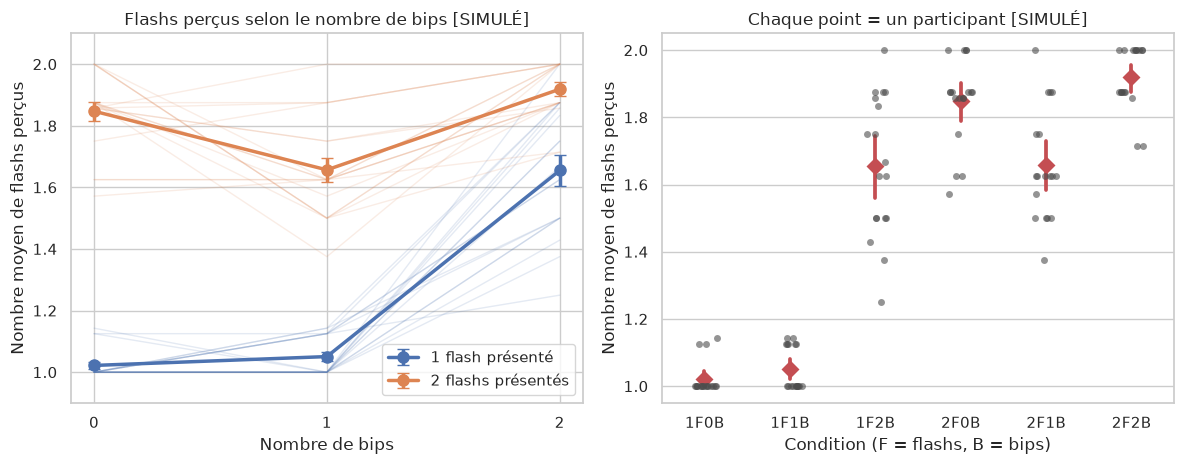

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ax = axes[0]
for (pid, nf), g in per_subj.groupby(["participant_id", "n_flashes"]):
    ax.plot(g.n_beeps, g.mean_flashes, color="C0" if nf == 1 else "C1", alpha=0.15, lw=1)
grp = per_subj.groupby(["n_flashes", "n_beeps"]).mean_flashes.agg(["mean", "sem"]).reset_index()
for nf, g in grp.groupby("n_flashes"):
    ax.errorbar(g.n_beeps, g["mean"], yerr=g["sem"], marker="o", ms=8, lw=2.5, capsize=4,
                color="C0" if nf == 1 else "C1", label=f"{nf} flash{'s' if nf > 1 else ''} présenté{'s' if nf > 1 else ''}")
ax.set_xticks([0, 1, 2]); ax.set_ylim(0.9, 2.1)
ax.set_xlabel("Nombre de bips"); ax.set_ylabel("Nombre moyen de flashs perçus")
ax.set_title("Flashs perçus selon le nombre de bips" + TAG); ax.legend()

ax = axes[1]
sns.stripplot(data=per_subj, x="cond", y="mean_flashes", order=ORDER, color="0.3", alpha=0.6, jitter=0.15, ax=ax)
sns.pointplot(data=per_subj, x="cond", y="mean_flashes", order=ORDER, color="C3", errorbar=("ci", 95),
              linestyle="none", markers="D", ax=ax)
ax.set_xlabel("Condition (F = flashs, B = bips)"); ax.set_ylabel("Nombre moyen de flashs perçus")
ax.set_title("Chaque point = un participant" + TAG)
plt.tight_layout(); plt.savefig(FIG_DIR / f"fig1_flashs_percus{SUFFIX}.png", dpi=150); plt.show()

### 3.2 Indices d'illusion par participant

- **Indice de fission** = P(« 2 » | 1F2B) − P(« 2 » | 1F0B) : combien de fois de plus on voit un 2e flash qui n'existe pas quand on ajoute un 2e bip.
- **Indice de fusion** = P(« 1 » | 2F1B) − P(« 1 » | 2F0B) : combien de fois de plus on « perd » un flash quand il n'y a qu'un bip.
- **Fission avec écart** = P(« 2 » | 1F2B_gap200) − P(« 2 » | 1F0B).

Les deux premiers indices sont sur la même échelle (une différence de proportions, référence = même nombre de flashs sans son) : on peut donc les comparer directement (H3).

In [7]:
p = d.groupby(["participant_id", "condition"]).agg(p2=("two", "mean"), n=("two", "size")).reset_index()
P2 = p.pivot(index="participant_id", columns="condition", values="p2")
N = p.pivot(index="participant_id", columns="condition", values="n")
idx = pd.DataFrame(index=P2.index)
idx["fission"] = P2["1F2B"] - P2["1F0B"]
idx["fusion"] = (1 - P2["2F1B"]) - (1 - P2["2F0B"])
idx["fission_gap200"] = P2["1F2B_gap200"] - P2["1F0B"]
display(idx.round(3))
display(idx.agg(["mean", "std", "count"]).round(3))
print("Nombre d'essais gardés par condition (min) :", N.min().to_dict())

,fission,fusion,fission_gap200
participant_id,,,
SIMULATED-01,0.5,0,0
SIMULATED-02,0.125,0.5,0.375
SIMULATED-03,0.5,-0.125,0
SIMULATED-04,0.5,0,0.333
SIMULATED-05,0.667,0.107,0.667
SIMULATED-06,0.375,-0.143,0.167
SIMULATED-07,0.625,-0.018,0
SIMULATED-08,0.375,0.304,0.042
SIMULATED-09,0.429,0.375,0.333


,fission,fusion,fission_gap200
mean,0.633,0.19,0.224
std,0.227,0.231,0.211
count,18,18,18


Nombre d'essais gardés par condition (min) : {'1F0B': 7, '1F1B': 7, '1F2B': 6, '1F2B_gap200': 5, '2F0B': 7, '2F0B_catch': 3, '2F1B': 7, '2F2B': 7}


## 4. Tests

Tests de Student **appariés** (chaque participant est son propre contrôle), unilatéraux dans le sens prédit, avec la taille d'effet d de Cohen ; un test de Wilcoxon (non paramétrique) sert de vérification, car avec 8 essais par condition les proportions ne prennent que 9 valeurs possibles.

### H1 (fission) et H2 (fusion)

In [8]:
def paired(a, b, label, alternative="greater"):
    a, b = a.dropna(), b.dropna()
    common = a.index.intersection(b.index)
    a, b = a[common], b[common]
    t = pg.ttest(a, b, paired=True, alternative=alternative)
    w = stats.wilcoxon(a, b, alternative=alternative, zero_method="zsplit")
    out = t[["T", "dof", "p_val" if "p_val" in t else "p-val", "cohen_d" if "cohen_d" in t else "cohen-d"]].copy()
    out.columns = ["t", "ddl", "p", "d"]
    out.insert(0, "diff_moy", (a - b).mean())
    out["p_wilcoxon"] = w.pvalue
    out.index = [label]
    return out

res = pd.concat([
    paired(P2["1F2B"], P2["1F0B"], "H1 fission : P(2|1F2B) > P(2|1F0B)"),
    paired(P2["1F2B"], P2["1F1B"], "H1 bis : P(2|1F2B) > P(2|1F1B)"),
    paired(1 - P2["2F1B"], 1 - P2["2F0B"], "H2 fusion : P(1|2F1B) > P(1|2F0B)"),
])
display(res)

,diff_moy,t,ddl,p,d,p_wilcoxon
H1 fission : P(2|1F2B) > P(2|1F0B),0.6329,11.81,17,6.404e-10,4.153,9.634e-05
H1 bis : P(2|1F2B) > P(2|1F1B),0.6042,11.14,17,1.562e-09,3.891,9.567e-05
H2 fusion : P(1|2F1B) > P(1|2F0B),0.1905,3.498,17,0.001379,1.281,0.00684


### H3 : la fission est-elle plus forte que la fusion ?

Comparaison appariée des deux indices (Andersen et al., 2004, trouvent une fission plus robuste que la fusion). On regarde aussi, à titre exploratoire, si les personnes sensibles à l'une le sont à l'autre (corrélation).

,diff_moy,t,ddl,p,d,p_wilcoxon
H3 : indice de fission > indice de fusion,0.4425,6.309,17,3.926e-06,1.93,0.0002244


Corrélation fission / fusion (exploratoire) :


,n,r,CI95,p_val,BF10,power
pearson,18,0.1574,"[-0.33, 0.58]",0.5329,0.349,0.0957


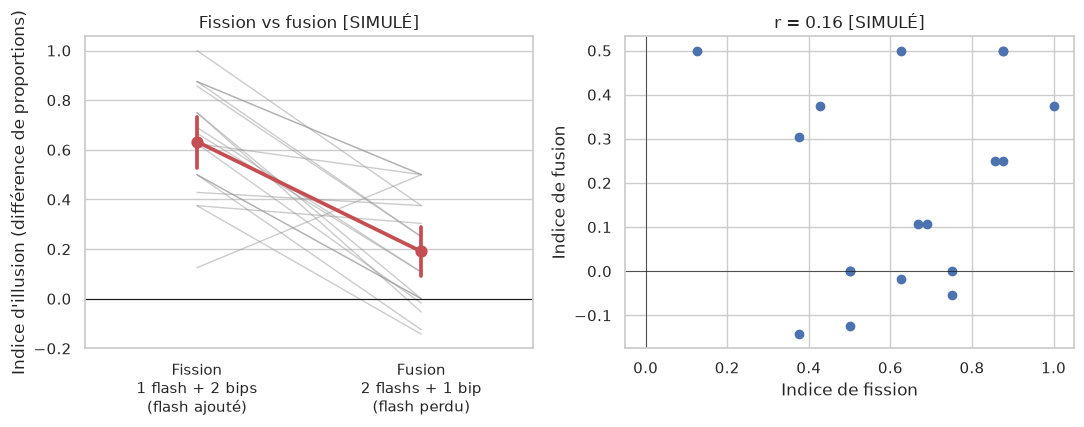

In [9]:
display(paired(idx.fission, idx.fusion, "H3 : indice de fission > indice de fusion"))
r = pg.corr(idx.fission, idx.fusion)
print("Corrélation fission / fusion (exploratoire) :"); display(r)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
ax = axes[0]
long = idx[["fission", "fusion"]].reset_index().melt(id_vars="participant_id", var_name="illusion", value_name="indice")
for pid, g in long.groupby("participant_id"):
    ax.plot([0, 1], g.set_index("illusion").loc[["fission", "fusion"], "indice"], color="0.6", alpha=0.5, lw=1)
sns.pointplot(data=long, x="illusion", y="indice", order=["fission", "fusion"], color="C3", errorbar=("ci", 95), ax=ax)
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks([0, 1], ["Fission\n1 flash + 2 bips\n(flash ajouté)", "Fusion\n2 flashs + 1 bip\n(flash perdu)"])
ax.set_xlabel(""); ax.set_ylabel("Indice d'illusion (différence de proportions)")
ax.set_title("Fission vs fusion" + TAG)
ax = axes[1]
ax.scatter(idx.fission, idx.fusion)
ax.axhline(0, color="k", lw=0.5); ax.axvline(0, color="k", lw=0.5)
ax.set_xlabel("Indice de fission"); ax.set_ylabel("Indice de fusion")
ax.set_title(f"r = {r['r'].iloc[0]:.2f}" + TAG)
plt.tight_layout(); plt.savefig(FIG_DIR / f"fig2_fission_fusion{SUFFIX}.png", dpi=150); plt.show()

### H4 : ANOVA à mesures répétées 2 (flashs) × 3 (bips) et modèle mixte

Variable dépendante : nombre moyen de flashs perçus par participant et condition. L'effet attendu est une **interaction** : ajouter des bips augmente le nombre perçu avec 1 flash (fission) et le diminue avec 2 flashs quand il n'y a qu'un bip (fusion). La correction de Greenhouse-Geisser est rapportée par pingouin. Le modèle mixte (ordonnée à l'origine aléatoire par participant) donne une vérification qui tolère les cellules manquantes.

In [10]:
aov = pg.rm_anova(data=per_subj, dv="mean_flashes", within=["n_flashes", "n_beeps"], subject="participant_id",
                  detailed=True, effsize="np2")
display(aov)
print(AnovaRM(per_subj, "mean_flashes", "participant_id", within=["n_flashes", "n_beeps"]).fit())

import warnings
with warnings.catch_warnings():
    # Si la variance entre participants est quasi nulle (fréquent avec des moyennes par condition),
    # statsmodels avertit que la variance aléatoire est « singulière » : les effets fixes restent valides.
    warnings.simplefilter("ignore")
    mm = smf.mixedlm("mean_flashes ~ C(n_flashes) * C(n_beeps)", per_subj, groups=per_subj["participant_id"]).fit()
print(mm.summary())

print("Comparaisons post hoc (correction de Holm) : effet des bips pour chaque nombre de flashs")
ph = pg.pairwise_tests(data=per_subj, dv="mean_flashes", within=["n_flashes", "n_beeps"],
                       subject="participant_id", padjust="holm")
display(ph[ph.Contrast.str.contains("n_flashes \\* n_beeps")])

,Source,SS,ddof1,ddof2,MS,F,p_unc,p_GG_corr,np2,eps,sphericity,W_spher,p_spher
0,n_flashes,8.624,1,17,8.624,569.5,1.64e-14,1.64e-14,0.971,1,True,NaN,1
1,n_beeps,3.817,2,34,1.909,137.1,5.32e-17,1.019e-16,0.8897,0.981,True,0.9806,0.8548
2,n_flashes * n_beeps,1.442,2,34,0.7208,29.77,3.373e-08,2.318e-07,0.6365,0.8644,True,0.8431,0.2552


                     Anova
                  F Value  Num DF  Den DF Pr > F
------------------------------------------------
n_flashes         569.4707 1.0000 17.0000 0.0000
n_beeps           137.0805 2.0000 34.0000 0.0000
n_flashes:n_beeps  29.7707 2.0000 34.0000 0.0000

                   Mixed Linear Model Regression Results
Model:                  MixedLM       Dependent Variable:       mean_flashes
No. Observations:       108           Method:                   REML        
No. Groups:             18            Scale:                    0.0174      
Min. group size:        6             Log-Likelihood:           53.2733     
Max. group size:        6             Converged:                Yes         
Mean group size:        6.0                                                 
----------------------------------------------------------------------------
                                  Coef.  Std.Err.   z    P>|z| [0.025 0.975]
------------------------------------------------------

,Contrast,n_flashes,A,B,Paired,Parametric,T,dof,alternative,p_unc,p_corr,p_adjust,BF10,hedges
4,n_flashes * n_beeps,1,0,1,True,True,-1.427,17,two-sided,0.1718,0.2462,holm,0.577,-0.4817
5,n_flashes * n_beeps,1,0,2,True,True,-11.81,17,two-sided,1.281e-09,7.685e-09,holm,8.22e+06,-4.061
6,n_flashes * n_beeps,1,1,2,True,True,-11.14,17,two-sided,3.124e-09,1.562e-08,holm,3.596e+06,-3.805
7,n_flashes * n_beeps,2,0,1,True,True,3.498,17,two-sided,0.002758,0.008275,holm,15.632,1.252
8,n_flashes * n_beeps,2,0,2,True,True,-1.622,17,two-sided,0.1231,0.2462,holm,0.731,-0.6133
9,n_flashes * n_beeps,2,1,2,True,True,-6.576,17,two-sided,4.71e-06,1.884e-05,holm,4365.417,-1.885


### H5 : la fission diminue-t-elle quand les bips sont plus espacés ?

Le cerveau n'associe un son et une image que s'ils sont assez proches dans le temps (« fenêtre d'intégration »). Shams et al. (2000) observent l'illusion jusqu'à environ 100 ms entre les bips. On compare P(« 2 ») pour 1 flash + 2 bips à 57 ms et à 200 ms.

,diff_moy,t,ddl,p,d,p_wilcoxon
H5 : P(2|bips à 57 ms) > P(2|bips à 200 ms),0.4085,5.939,17,8.08e-06,1.949,0.0002899
Reste-t-il une fission à 200 ms ? (exploratoire),0.2245,4.505,17,0.0001562,1.473,0.0002154


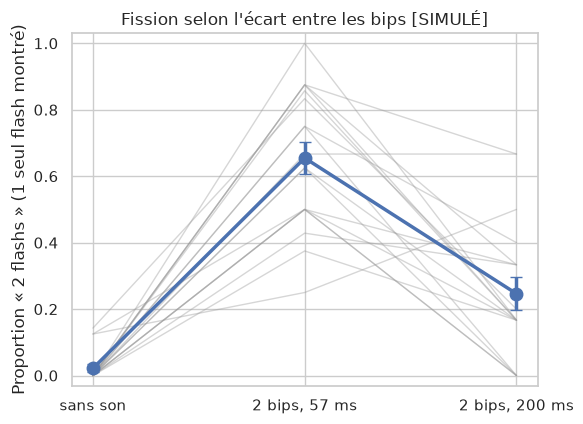

In [11]:
display(pd.concat([
    paired(P2["1F2B"], P2["1F2B_gap200"], "H5 : P(2|bips à 57 ms) > P(2|bips à 200 ms)"),
    paired(P2["1F2B_gap200"], P2["1F0B"], "Reste-t-il une fission à 200 ms ? (exploratoire)"),
]))

gap = P2[["1F0B", "1F2B", "1F2B_gap200"]].rename(columns={"1F0B": "sans son", "1F2B": "2 bips, 57 ms",
                                                          "1F2B_gap200": "2 bips, 200 ms"})
fig, ax = plt.subplots(figsize=(6, 4.4))
for pid, row in gap.iterrows():
    ax.plot(range(3), row.values, color="0.6", alpha=0.4, lw=1)
ax.errorbar(range(3), gap.mean(), yerr=gap.sem(), color="C0", marker="o", ms=9, lw=2.5, capsize=4)
ax.set_xticks(range(3), gap.columns); ax.set_ylim(-0.03, 1.03)
ax.set_ylabel("Proportion « 2 flashs » (1 seul flash montré)")
ax.set_title("Fission selon l'écart entre les bips" + TAG)
plt.tight_layout(); plt.savefig(FIG_DIR / f"fig3_ecart_bips{SUFFIX}.png", dpi=150); plt.show()

### Vérification sur les données simulées

Uniquement avec les données simulées : les indices estimés retrouvent-ils les vrais paramètres utilisés pour générer les faux participants ? (Avec 8 essais par condition, l'estimation individuelle est bruitée : c'est une limite à garder en tête.)

In [12]:
if SIMULATED and (SIM_DIR / "ground_truth_SIMULATED.txt").exists():
    truth = pd.read_csv(SIM_DIR / "ground_truth_SIMULATED.txt", sep="\t", comment="#")
    truth.index = "SIMULATED-" + truth.participant_id.str[3:]
    cmp = idx.join(truth[["amp", "fusion"]].rename(columns={"fusion": "fusion_vraie"}), how="inner")
    print("Corrélation fission estimée / force vraie :", round(cmp.fission.corr(cmp.amp), 2))
    print("Corrélation fusion estimée / fusion vraie :", round(cmp.fusion.corr(cmp.fusion_vraie), 2))
else:
    print("Données réelles : pas de vérité terrain.")

Corrélation fission estimée / force vraie : 0.49
Corrélation fusion estimée / fusion vraie : 0.34


## 5. Perception ou biais de réponse ? (exploratoire, détection du signal)

Répondre « 2 » avec deux bips pourrait refléter un **biais de décision** (« j'ai entendu 2, je dis 2 ») plutôt qu'un vrai changement de perception. On calcule la **sensibilité d′** à la différence 1 vs 2 flashs, avec 2 bips (signal = 2F2B, bruit = 1F2B) et sans son (signal = 2F0B, bruit = 1F0B). Si les bips rendent les flashs perceptivement indiscernables, d′ baisse. Le critère c mesure le biais (c < 0 : tendance à répondre « 2 »). Taux extrêmes corrigés : 0 → 0,5/N, 1 → (N − 0,5)/N.

In [13]:
def rate(x):
    n, k = len(x), x.sum()
    return min(max(k / n, 0.5 / n), (n - 0.5) / n)

rows = []
for pid, g in core.groupby("participant_id"):
    out = {"participant_id": pid}
    for lab, sig, noise in [("son", "2F2B", "1F2B"), ("sans_son", "2F0B", "1F0B")]:
        H, F = rate(g[g.condition == sig].two), rate(g[g.condition == noise].two)
        out[f"dprime_{lab}"] = stats.norm.ppf(H) - stats.norm.ppf(F)
        out[f"c_{lab}"] = -0.5 * (stats.norm.ppf(H) + stats.norm.ppf(F))
    rows.append(out)
sdt = pd.DataFrame(rows).set_index("participant_id")
display(sdt.agg(["mean", "std"]).round(2))
display(pd.concat([paired(sdt.dprime_sans_son, sdt.dprime_son, "d′ sans son > d′ avec 2 bips"),
                   paired(sdt.c_sans_son, sdt.c_son, "c sans son > c avec 2 bips")]))

,dprime_son,c_son,dprime_sans_son,c_sans_son
mean,0.81,-0.86,2.48,0.2
std,0.83,0.26,0.41,0.23


,diff_moy,t,ddl,p,d,p_wilcoxon
d′ sans son > d′ avec 2 bips,1.673,6.57,17,2.383e-06,2.565,9.805e-05
c sans son > c avec 2 bips,1.061,13.89,17,5.219e-11,4.257,9.805e-05


## 6. Diagnostics de timing

Le navigateur ne peut pas mesurer l'instant où la lumière sort de l'écran ni celui où le son sort du casque. On enregistre ce qu'il peut observer : fréquence de l'écran, images perdues, retard du flash par rapport à l'image prévue, avance de programmation du son, dérive entre horloges audio et page, latence de sortie audio annoncée. Ces mesures alimentent les critères d'exclusion.

,audio,refresh_hz,images_perdues,retard_flash_moy_ms,duree_flash_ms,avance_son_min_ms,derive_horloges_max_ms,latence_sortie_ms,essais_exclus,mapping
participant_id,,,,,,,,,,
SIMULATED-01,speakers,144,0,-0.41,13.89,220.2,0.28,26.25,0,outputTimestamp
SIMULATED-02,speakers,120,1,-0.27,16.7,221.1,0.28,23.55,0.02,outputTimestamp
SIMULATED-03,wired,144,0,-0.37,13.92,222.3,0.29,22.55,0,outputTimestamp
SIMULATED-04,speakers,120,1,-0.29,16.7,220.3,0.21,21.8,0.02,outputTimestamp
SIMULATED-05,speakers,120,4,0.17,16.68,220.1,0.26,22.85,0.07,outputTimestamp
SIMULATED-06,wired,60,1,-0.14,16.66,220.2,0.24,19.05,0.02,outputTimestamp
SIMULATED-07,speakers,60,1,-0.13,16.68,220.6,0.32,19.8,0.02,outputTimestamp
SIMULATED-08,speakers,144,1,-0.29,13.84,220.2,0.2,20.2,0.02,outputTimestamp
SIMULATED-09,wired,60,2,0.18,16.69,221.3,0.27,23.95,0.03,outputTimestamp


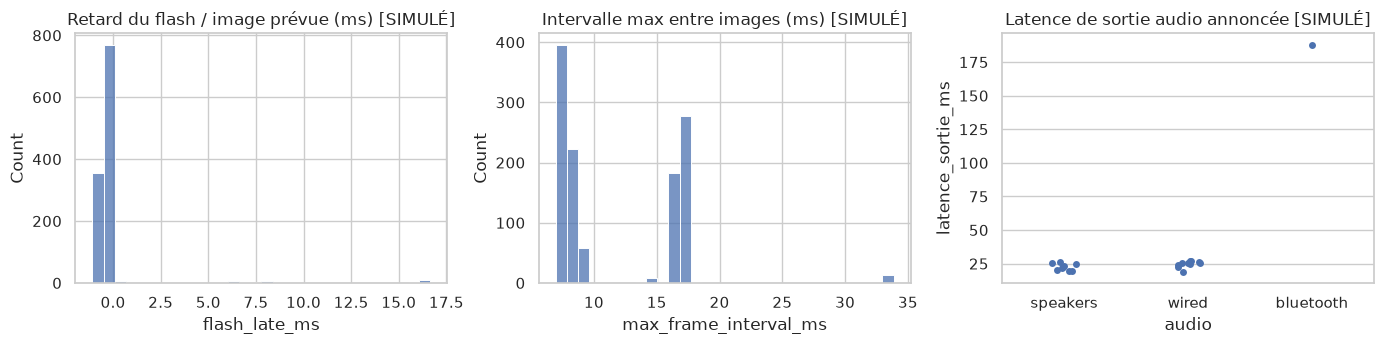

In [14]:
diag = main.groupby("participant_id").agg(
    audio=("audio_device", "first"), refresh_hz=("refresh_hz", "median"),
    images_perdues=("n_dropped_frames", "sum"), retard_flash_moy_ms=("flash_late_ms", "mean"),
    duree_flash_ms=("flash_dur_ms_actual", "median"),
    avance_son_min_ms=("audio_lead_ms", "min"), derive_horloges_max_ms=("audio_clock_drift_ms", lambda s: s.abs().max()),
    latence_sortie_ms=("output_latency_ms", "median"), essais_exclus=("exclude_trial", "mean"),
    mapping=("audio_mapping", "first"))
display(diag.round(2))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
sns.histplot(main.flash_late_ms.dropna(), bins=30, ax=axes[0]); axes[0].set_title("Retard du flash / image prévue (ms)" + TAG)
sns.histplot(main.max_frame_interval_ms.dropna(), bins=30, ax=axes[1]); axes[1].set_title("Intervalle max entre images (ms)" + TAG)
sns.stripplot(data=diag.reset_index(), x="audio", y="latence_sortie_ms", ax=axes[2])
axes[2].set_title("Latence de sortie audio annoncée" + TAG)
plt.tight_layout(); plt.savefig(FIG_DIR / f"fig4_timing{SUFFIX}.png", dpi=150); plt.show()

## 7. Conclusion

*(À rédiger une fois les vraies données collectées : ne rien conclure à partir des données simulées.)*

Points à rapporter :
1. Nombre de sessions reçues, exclues (et pourquoi), analysées ;
2. **H1** : t(ddl) = …, p = …, d = … — fission répliquée en ligne ? Ampleur comparée à l'article (≈ 1,9 flash perçu pour 1 flash + 2 bips chez Shams et al., 2000) ;
3. **H2** : fusion (Shams et al. 2000 n'en trouvent pas ; Andersen et al. 2004 en trouvent une, plus faible) ;
4. **H3** : fission > fusion ? Interprétation : le son influence surtout la vision quand il apporte une information temporelle *supplémentaire* (un événement de plus) ;
5. **H4** : interaction flashs × bips de l'ANOVA ;
6. **H5** : baisse de la fission à 200 ms → fenêtre d'intégration temporelle limitée ;
7. Détection du signal : effet perceptif (d′) ou biais (c) ?
8. Limites : timing du navigateur (son et image non mesurés physiquement), matériel hétérogène, échantillon de convenance, 8 essais par condition (indices individuels bruités), participants pouvant refaire l'expérience (données anonymes).